# Optimal sensor placement with QR pivoting, in pictures

Compressed sensing assumes only that a signal is sparse in a *generic*
basis, and it measures at random locations. When we have training data we
can do better. We learn a tailored basis $\boldsymbol{\Psi}_r$ with only
$r\ll n$ columns, and then we *choose* where to put $p$ point sensors. This
notebook shows every matrix of that pipeline as a coloured block picture on a
tiny 1-D example, and then checks with brute force that the greedy QR choice
is (close to) the best possible one.

**In this notebook you will**

* build a POD basis $\boldsymbol{\Psi}_r$ from snapshot data with the SVD;
* see the four matrix equations $\boldsymbol{x}=\boldsymbol{\Psi}_r\boldsymbol{a}$,
  $\boldsymbol{y}=\mathbf{C}\boldsymbol{\Psi}_r\boldsymbol{a}$,
  $\boldsymbol{y}=\boldsymbol{\Theta}\boldsymbol{a}$ and
  $\boldsymbol{\Psi}_r^\top\mathbf{P}=\mathbf{Q}\mathbf{R}$ as block pictures;
* learn what QR with column pivoting does, step by step, and why its pivots are good sensors;
* compare QR against all 35,960 possible sensor sets of a small problem;
* see what happens when you have more sensors than modes ($p>r$).

**Before this notebook:** `cs_portrait_fista` (the last of the compressed
sensing notebooks). The least-squares and SVD ideas used here are
self-contained.

**Next:** `cs_sensor_placement`, the same method on a 2560-point wind-farm
wake field.

**Runtime:** a few seconds.

### The setting in one line of equations

$$\boldsymbol{x}\approx\boldsymbol{\Psi}_r\boldsymbol{a},\qquad
  \boldsymbol{y}=\mathbf{C}\boldsymbol{x}=\mathbf{C}\boldsymbol{\Psi}_r\boldsymbol{a}
  =\boldsymbol{\Theta}\boldsymbol{a},\qquad
  \hat{\boldsymbol{a}}=\boldsymbol{\Theta}^{+}\boldsymbol{y},\qquad
  \hat{\boldsymbol{x}}=\boldsymbol{\Psi}_r\hat{\boldsymbol{a}} .$$

* $\boldsymbol{x}\in\mathbb{R}^{n}$: the full state (the field at all $n$ grid points).
* $\boldsymbol{\Psi}_r\in\mathbb{R}^{n\times r}$: the basis, $r$ orthonormal spatial modes.
* $\boldsymbol{a}\in\mathbb{R}^{r}$: the modal coefficients, the only unknowns.
* $\mathbf{C}\in\mathbb{R}^{p\times n}$: the measurement matrix. Each row has a single 1
  in the column of a sensor location, so $\mathbf{C}\boldsymbol{x}$ just picks $p$ entries of $\boldsymbol{x}$.
* $\boldsymbol{y}\in\mathbb{R}^{p}$: the $p$ sensor readings.
* $\boldsymbol{\Theta}=\mathbf{C}\boldsymbol{\Psi}_r\in\mathbb{R}^{p\times r}$: the rows of
  $\boldsymbol{\Psi}_r$ at the sensor locations.
* $\boldsymbol{\Theta}^{+}$: the pseudo-inverse, i.e. the least-squares solution
  $\hat{\boldsymbol{a}}=\arg\min_{\boldsymbol{a}}\|\boldsymbol{y}-\boldsymbol{\Theta}\boldsymbol{a}\|_2^2$.
  Reconstructing a field this way from a few point values is called **gappy POD**.

### Why the choice of sensors matters

Suppose each reading has independent noise of variance $\eta^2$, so
$\boldsymbol{y}=\boldsymbol{\Theta}\boldsymbol{a}+\boldsymbol{\varepsilon}$ with
$\operatorname{Cov}(\boldsymbol{\varepsilon})=\eta^2\mathbf{I}$. The least-squares
estimate is
$\hat{\boldsymbol{a}}=(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})^{-1}\boldsymbol{\Theta}^\top\boldsymbol{y}$,
so its error $\hat{\boldsymbol{a}}-\boldsymbol{a}=(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})^{-1}\boldsymbol{\Theta}^\top\boldsymbol{\varepsilon}$
has covariance

$$\operatorname{Cov}(\hat{\boldsymbol{a}})=\eta^2(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})^{-1}.$$

A good sensor set therefore makes $\boldsymbol{\Theta}^\top\boldsymbol{\Theta}$
"large". Two ways to measure "large":

* the **determinant** $\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})$. The volume of the
  error ellipsoid is proportional to $1/\sqrt{\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})}$,
  so a large determinant means a small cloud of possible errors;
* the **condition number** $\operatorname{cond}(\boldsymbol{\Theta})=\sigma_{\max}/\sigma_{\min}$,
  the ratio of largest to smallest singular value. A large value means some
  combination of modes is barely seen by the sensors, and noise in that
  direction is amplified.

The **D-optimal** sensor set maximises the determinant over all index sets
$\gamma$ of size $p$ (and $\mathbf{C}_\gamma$ is the matching selection matrix):

$$\gamma^\star=\arg\max_{|\gamma|=p}\ \det\!\big[(\mathbf{C}_\gamma\boldsymbol{\Psi}_r)^\top
  (\mathbf{C}_\gamma\boldsymbol{\Psi}_r)\big].$$

That is a search over $\binom{n}{p}$ subsets, which is hopeless for real
grids. **QR with column pivoting** of $\boldsymbol{\Psi}_r^\top$ is a greedy
approximation: $\boldsymbol{\Psi}_r^\top\mathbf{P}=\mathbf{Q}\mathbf{R}$, and the
first $p$ pivots (the columns that $\mathbf{P}$ moves to the front) are the
sensors. For $p>r$ we pivot on $\boldsymbol{\Psi}_r\boldsymbol{\Psi}_r^\top$ instead.

## Setup

Standard imports. `pyutils` is the course helper package: `save_dual` writes
every figure in a light and a dark version to `../figures`, and `fg()` and
`muted()` return the theme's foreground and grey colours.

In [1]:
import sys, os
from itertools import combinations
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.linalg import qr
from pyutils import set_plot_style, save_dual, fg, muted
set_plot_style()

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

## Parameters (edit these)

* `SEED`: seed of the random generator (field shapes, amplitudes, random sensor sets).
* `N_PIC`, `R_PIC`: grid size $n$ and number of modes $r$ for the block pictures.
  We use $p=r$ sensors there, so $\boldsymbol{\Theta}$ is square.
* `N_BF`, `R_BF`: grid size and number of modes for the brute-force study.
  The number of subsets $\binom{n}{r}$ grows very fast, so keep these small.
* `N_SNAP`: number of training snapshots (columns of the snapshot matrix).
* `NOISE`: sensor noise standard deviation, as a fraction of the field RMS.
* `P_OVER`: the sensor counts $p$ tried in the oversampling study.
* `N_RAND`: how many random sensor sets are drawn for each $p$.

In [2]:
SEED = 3
N_PIC, R_PIC = 16, 5          # block pictures: grid points, POD modes (= sensors)
N_BF, R_BF = 32, 4            # brute-force D-optimality study: C(32, 4) = 35,960 subsets
N_SNAP = 400                  # training snapshots
NOISE = 0.02                  # sensor noise (relative to field RMS) for the error study
P_OVER = range(4, 13)         # sensor counts for the oversampling study (r = R_BF)
N_RAND = 500                  # random sensor sets per p

rng = np.random.default_rng(SEED)

## 1. A field with $r$ coherent structures, and its POD basis

**The data.** `make_field` builds a 1-D profile on $n$ grid points from $r$
smooth spatial shapes: $r-1$ Gaussian bumps at different positions and widths,
plus one large-scale linear tilt. Each shape gets its own random amplitude in
every snapshot, and a tiny amount of noise ($10^{-3}$) is added. Stacking the
$N_s$ snapshots as columns gives the **snapshot matrix**
$\mathbf{X}=[\boldsymbol{x}_1,\dots,\boldsymbol{x}_{N_s}]\in\mathbb{R}^{n\times N_s}$.

**POD from the SVD.** Write the thin SVD
$\mathbf{X}=\mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^\top$. The columns of
$\mathbf{U}$ are orthonormal spatial patterns, ordered by the singular values
$\sigma_1\ge\sigma_2\ge\dots$ on the diagonal of $\boldsymbol{\Sigma}$. The POD
basis is the first $r$ left singular vectors,
$\boldsymbol{\Psi}_r=\mathbf{U}_{:,1:r}$. Among all $r$-dimensional subspaces it
gives the smallest average squared projection error of the snapshots. The
**energy fraction** captured by $r$ modes is

$$E_r=\frac{\sum_{k=1}^{r}\sigma_k^2}{\sum_{k}\sigma_k^2}.$$

Because the field was built from exactly $r$ shapes, $E_r$ should be 1 up to
the tiny noise.

**The helpers.** `qr_sensors(Psi_r, p)` returns the first $p$ pivots of a
pivoted QR (on $\boldsymbol{\Psi}_r^\top$ when $p\le r$, on
$\boldsymbol{\Psi}_r\boldsymbol{\Psi}_r^\top$ when $p>r$). `logdet(Psi_r, idx)`
returns $\log\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})$ for the sensor set
`idx`; working with the logarithm avoids underflow of very small determinants.

**The worked example.** We then take one snapshot $\boldsymbol{x}$, compute its
true modal coefficients $\boldsymbol{a}=\boldsymbol{\Psi}_r^\top\boldsymbol{x}$
(valid because the columns of $\boldsymbol{\Psi}_r$ are orthonormal), place
$p=r$ sensors with QR, build $\mathbf{C}$ and
$\boldsymbol{\Theta}=\mathbf{C}\boldsymbol{\Psi}_r$, read
$\boldsymbol{y}=\mathbf{C}\boldsymbol{x}$, and solve the square system
$\boldsymbol{\Theta}\hat{\boldsymbol{a}}=\boldsymbol{y}$. The asserts check
the factorisation, the ordering of $\mathbf{R}$'s diagonal, and that
$\hat{\boldsymbol{a}}\approx\boldsymbol{a}$.

In [3]:
def make_field(n, r, n_snap, rng):
    xi = np.linspace(0, 1, n)
    centres = np.linspace(0.12, 0.88, r - 1)
    widths = rng.uniform(0.05, 0.12, r - 1)
    shapes = [np.exp(-((xi - c) / w) ** 2) for c, w in zip(centres, widths)] + [xi - 0.5]
    Phi = np.column_stack(shapes)                       # (n, r) true spatial shapes
    amps = rng.standard_normal((r, n_snap)) * np.linspace(1.5, 0.6, r)[:, None]
    X = Phi @ amps + 1e-3 * rng.standard_normal((n, n_snap))   # snapshot matrix, (n, n_snap)
    U, sv, _ = np.linalg.svd(X, full_matrices=False)
    return xi, X, U[:, :r], sv                          # U[:, :r] is the POD basis Psi_r


def qr_sensors(Psi_r, p):
    r = Psi_r.shape[1]
    M = Psi_r.T if p <= r else Psi_r @ Psi_r.T          # (r, n) or (n, n): one column per grid point
    _, _, piv = qr(M, pivoting=True, mode='economic')   # piv = column order chosen by pivoting
    return np.sort(piv[:p])


def logdet(Psi_r, idx):
    Th = Psi_r[idx]                                     # Theta = C Psi_r = the rows of Psi_r at the sensors
    return np.linalg.slogdet(Th.T @ Th)[1]              # log det(Theta^T Theta), safe for tiny values


xi, X, PSI_R, sv = make_field(N_PIC, R_PIC, N_SNAP, rng)
energy = np.cumsum(sv ** 2) / np.sum(sv ** 2)           # E_r for r = 1, 2, ...
print(f"n={N_PIC}: energy captured by r={R_PIC} modes: {energy[R_PIC-1]:.6f}")
assert energy[R_PIC - 1] > 0.9999, "the field must be r-dimensional up to the noise"

# one snapshot, its modal coefficients, and the QR sensors
x_snap = X[:, 7]
a = PSI_R.T @ x_snap                                    # true coefficients (orthonormal basis)
_, R_qr, piv = qr(PSI_R.T, pivoting=True)
Q_qr = qr(PSI_R.T, pivoting=True)[0]
sensors = np.sort(piv[:R_PIC])
C = np.zeros((R_PIC, N_PIC)); C[np.arange(R_PIC), sensors] = 1.0   # one 1 per row, at a sensor
THETA = C @ PSI_R
y = C @ x_snap
a_hat = np.linalg.solve(THETA, y)                       # p = r: Theta is square, so solve directly
assert np.allclose(PSI_R.T[:, piv], Q_qr @ R_qr), "Psi_r^T P = Q R"
assert np.allclose(np.abs(np.diag(R_qr)), np.sort(np.abs(np.diag(R_qr)))[::-1]), "pivoting orders |r_ii|"
assert np.allclose(a_hat, a, atol=1e-2), "r well-placed sensors recover the modal coefficients"
print("QR sensors:", sensors, "  cond(Theta) =", round(np.linalg.cond(THETA), 2))

n=16: energy captured by r=5 modes: 0.999999
QR sensors: [ 0  2  6  9 13]   cond(Theta) = 1.69


The $r=5$ POD modes capture an energy fraction of 0.999999, so this field is
5-dimensional up to the small added noise. QR picks the grid points
$[0, 2, 6, 9, 13]$ out of 16. The resulting $5\times5$ matrix
$\boldsymbol{\Theta}$ has condition number 1.69 (the ideal value is 1), so
solving for $\hat{\boldsymbol{a}}$ barely amplifies noise, and all asserts pass.

## 2. Block pictures

The next cell only defines drawing helpers; it computes nothing new.
`draw_vector` and `draw_matrix` paint each entry as a coloured cell, write the
symbol above the block and its dimensions below, and can outline chosen rows
or columns in orange. Vectors use the `plasma` colour map and matrices the
diverging `coolwarm` map (blue negative, red positive, pale near zero). The
colour limits `NX`, `NA`, `NP` are shared between pictures, so the same
value always has the same colour in every figure: an entry of
$\boldsymbol{y}$ has exactly the colour of the matching entry of
$\boldsymbol{x}$.

In [4]:
def draw_vector(ax, v, x0, y0, label, dims, cmap='plasma', norm=None, hl=None):
    k = len(v)
    if norm is None:
        lim = np.max(np.abs(v)); norm = Normalize(-lim, lim)
    ax.imshow(np.asarray(v, float).reshape(k, 1), cmap=cmap, norm=norm, aspect='auto',
              extent=[x0, x0 + 1, y0, y0 + k], interpolation='nearest')
    for i in range(k + 1):
        ax.plot([x0, x0 + 1], [y0 + i, y0 + i], color=fg(), lw=0.6)
    ax.plot([x0, x0 + 1, x0 + 1, x0, x0], [y0, y0, y0 + k, y0 + k, y0], color=fg(), lw=1.1)
    if hl is not None:                      # highlight rows (sensor locations)
        for i in hl:
            yy = y0 + k - 1 - i
            ax.plot([x0 - 0.15, x0 + 1.15, x0 + 1.15, x0 - 0.15, x0 - 0.15],
                    [yy, yy, yy + 1, yy + 1, yy], color='C1', lw=2.0)
    ax.text(x0 + 0.5, y0 + k + 0.9, label, ha='center', fontsize=17)
    ax.text(x0 + 0.5, y0 - 1.3, dims, ha='center', fontsize=12)


def draw_matrix(ax, M, x0, y0, label, dims, cmap='coolwarm', norm=None, hl_rows=None, hl_cols=None):
    r, c = M.shape
    if norm is None:
        lim = np.max(np.abs(M)); norm = Normalize(-lim, lim)
    ax.imshow(M, cmap=cmap, norm=norm, aspect='auto', extent=[x0, x0 + c, y0, y0 + r],
              interpolation='nearest')
    ax.plot([x0, x0 + c, x0 + c, x0, x0], [y0, y0, y0 + r, y0 + r, y0], color=fg(), lw=1.1)
    for i in (hl_rows or []):
        yy = y0 + r - 1 - i                 # row 0 is drawn at the top
        ax.plot([x0, x0 + c, x0 + c, x0, x0], [yy, yy, yy + 1, yy + 1, yy], color='C1', lw=2.0)
    if hl_cols is not None:
        c0, c1 = hl_cols
        ax.plot([x0 + c0, x0 + c1, x0 + c1, x0 + c0, x0 + c0], [y0, y0, y0 + r, y0 + r, y0],
                color='C1', lw=2.2)
    ax.text(x0 + c / 2, y0 + r + 0.9, label, ha='center', fontsize=17)
    ax.text(x0 + c / 2, y0 - 1.3, dims, ha='center', fontsize=12)


def sym(ax, xc, yc, s='$=$'):
    ax.text(xc, yc, s, ha='center', va='center', fontsize=22)


def finish(ax):
    ax.set_aspect('equal'); ax.axis('off')


n, r = N_PIC, R_PIC
NX = Normalize(-np.max(np.abs(x_snap)), np.max(np.abs(x_snap)))   # shared colour scale for x and y
NA = Normalize(-np.max(np.abs(a)), np.max(np.abs(a)))             # colour scale for a
NP = Normalize(-np.max(np.abs(PSI_R)), np.max(np.abs(PSI_R)))     # colour scale for Psi_r and Theta
L = dict(x=r'$\boldsymbol{x}$', y=r'$\boldsymbol{y}$', a=r'$\boldsymbol{a}$',
         C=r'$\mathbf{C}$', Psi=r'$\boldsymbol{\Psi}_r$', Th=r'$\boldsymbol{\Theta}$')


def plot_osp_modal():
    fig, ax = plt.subplots(figsize=(5.5, 5))
    draw_vector(ax, x_snap, 0, 0, L['x'], r'$n\times1$', norm=NX)
    sym(ax, 1.8, n / 2)
    draw_matrix(ax, PSI_R, 2.5, 0, L['Psi'], r'$n\times r$', norm=NP)
    draw_vector(ax, a, 3.2 + r, n - r, L['a'], r'$r\times1$', norm=NA)
    finish(ax)


def plot_osp_measure():
    fig, ax = plt.subplots(figsize=(10, 5))
    draw_vector(ax, y, 0, n - r, L['y'], r'$p\times1$', norm=NX)
    sym(ax, 1.8, n - r / 2)
    draw_matrix(ax, C, 2.5, n - r, L['C'], r'$p\times n$', cmap='Greys', norm=Normalize(0, 1))
    draw_matrix(ax, PSI_R, 3.5 + n, 0, L['Psi'], r'$n\times r$', norm=NP, hl_rows=list(sensors))
    draw_vector(ax, a, 4.2 + n + r, n - r, L['a'], r'$r\times1$', norm=NA)
    finish(ax)


def plot_osp_theta():
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    draw_vector(ax, y, 0, 0, L['y'], r'$p\times1$', norm=NX)
    sym(ax, 1.8, r / 2)
    draw_matrix(ax, THETA, 2.5, 0, L['Th'] + r'$=\mathbf{C}\boldsymbol{\Psi}_r$', r'$p\times r$', norm=NP)
    draw_vector(ax, a, 3.2 + r, 0, L['a'], r'$r\times1$', norm=NA)
    finish(ax)


def plot_osp_qr():
    PT = PSI_R.T[:, piv]
    gap = 1.0
    fig, ax = plt.subplots(figsize=(12, 3.4))
    draw_matrix(ax, PSI_R.T, 0, 0, r'$\boldsymbol{\Psi}_r^{\top}$', r'$r\times n$', norm=NP)
    for j in sensors:                                   # mark sensor columns
        ax.plot([j, j + 1, j + 1, j, j], [0, 0, r, r, 0], color='C1', lw=2.0)
    ax.text(n + 0.9, r / 2, r'$\mathbf{P}$', fontsize=20, ha='center', va='center')
    sym(ax, n + 2.4, r / 2)
    x0 = n + 3.4
    draw_matrix(ax, Q_qr, x0, 0, r'$\mathbf{Q}$', r'$r\times r$', norm=Normalize(-1, 1))
    x1 = x0 + r + gap
    lim = np.max(np.abs(R_qr))
    Rm = np.ma.masked_where(np.abs(R_qr) < 1e-12, R_qr)   # blank out the zeros below the diagonal
    draw_matrix(ax, Rm, x1, 0, r'$\mathbf{R}$', r'$r\times n$', norm=Normalize(-lim, lim), hl_cols=(0, r))
    for j in range(r):                                  # pivot labels under R
        ax.text(x1 + j + 0.5, -0.45, f'{piv[j]}', ha='center', va='top', fontsize=8, color='C1')
    finish(ax)

### 2a. The modal expansion $\boldsymbol{x}=\boldsymbol{\Psi}_r\boldsymbol{a}$

The first picture shows how one snapshot is built from the POD modes.

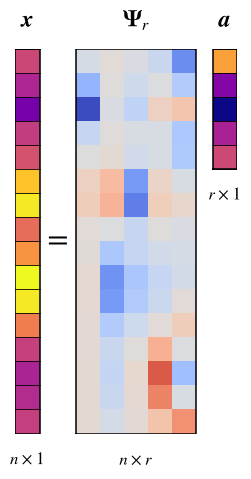

In [5]:
save_dual(plot_osp_modal, 'osp_block_modal', FIG)
plt.show()

**How to read this figure.** Left: the snapshot $\boldsymbol{x}$, a column of
$n=16$ cells (one per grid point, top cell is grid point 0). Middle:
$\boldsymbol{\Psi}_r$, $16\times5$; each of its 5 columns is one POD mode
drawn top to bottom (blue negative, red positive, pale near zero). Right:
$\boldsymbol{a}$, the $5\times1$ vector of modal coefficients, aligned with the
bottom of the equation only for layout. Read the picture as a matrix-vector
product: each cell of $\boldsymbol{x}$ is the row of $\boldsymbol{\Psi}_r$ next to
it, weighted by the entries of $\boldsymbol{a}$.

**What it shows.** 16 numbers are described exactly by 5 coefficients. You
can see the bumps in the modes: each column is strongly coloured over one or
two groups of neighbouring grid points and pale elsewhere. The unknown of the sensing
problem is therefore $\boldsymbol{a}$ with 5 entries, not $\boldsymbol{x}$ with 16.

### 2b. Point measurements $\boldsymbol{y}=\mathbf{C}\boldsymbol{\Psi}_r\boldsymbol{a}$

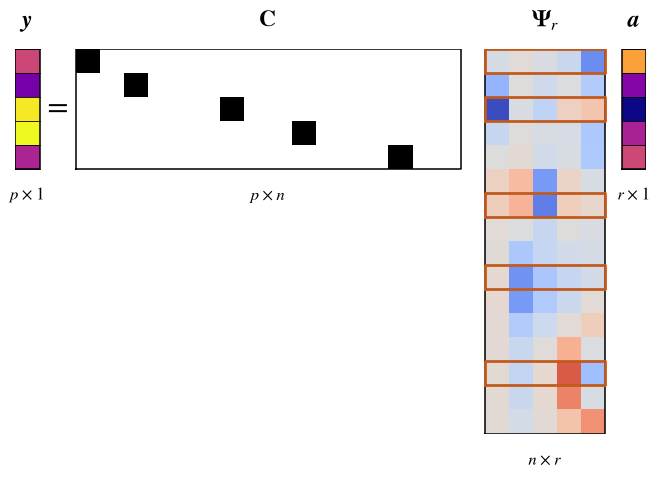

In [6]:
save_dual(plot_osp_measure, 'osp_block_measure', FIG)
plt.show()

**How to read this figure.** Left: the readings $\boldsymbol{y}$, $p\times1$
with $p=5$. Next: the measurement matrix $\mathbf{C}$, $5\times16$, drawn in
grey scale: every black cell is a 1 and white is 0. Row $i$ of $\mathbf{C}$
has its single 1 in the column of the $i$-th sensor. Then
$\boldsymbol{\Psi}_r$ ($16\times5$) and $\boldsymbol{a}$ ($5\times1$). The
orange boxes on $\boldsymbol{\Psi}_r$ mark the rows that $\mathbf{C}$ selects:
grid points 0, 2, 6, 9 and 13, the QR sensors printed above.

**What it shows.** Multiplying by $\mathbf{C}$ does no arithmetic: it simply
keeps 5 of the 16 rows. Compare colours with the previous picture: each cell
of $\boldsymbol{y}$ has the same colour as the cell of $\boldsymbol{x}$ at the
matching grid point. The black cells in $\mathbf{C}$ step down and to the
right, because the sensor indices are sorted.

### 2c. The small system $\boldsymbol{y}=\boldsymbol{\Theta}\boldsymbol{a}$

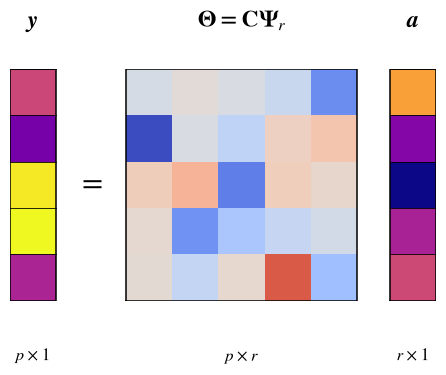

In [7]:
save_dual(plot_osp_theta, 'osp_block_theta', FIG)
plt.show()

**How to read this figure.** $\boldsymbol{\Theta}=\mathbf{C}\boldsymbol{\Psi}_r$ is
the $5\times5$ matrix made of the five orange-boxed rows of
$\boldsymbol{\Psi}_r$ from the previous picture, in the same colours. Left is
$\boldsymbol{y}$ ($5\times1$), right is $\boldsymbol{a}$ ($5\times1$).

**What it shows.** The whole sensing problem has shrunk to 5 equations in 5
unknowns. Each row of $\boldsymbol{\Theta}$ has one strongly coloured entry
in a different column, so every mode is seen clearly by some sensor. That is
what a condition number of 1.69 looks like. A badly placed set would contain
two rows that look alike, or a column that is pale everywhere (a mode no
sensor sees), and then $\boldsymbol{\Theta}$ would be close to singular.

## 3. Two modes, two sensors: what makes a sensor set good?

The five-mode pictures above show *what* the sensors measure. To see *why*
one sensor set is better than another, shrink the problem until everything
can be drawn: a string on $n=16$ grid points whose shape is a mix of $r=2$
patterns (the first two vibration modes), measured by $p=2$ point sensors.

Two kinds of numbers appear, and it is important not to mix them up:

* the **mode values** $\psi_{j1},\psi_{j2}$: the shape of mode 1 and mode 2
  at grid point $j$. They are fixed, learned once from data, and form row $j$
  of $\boldsymbol{\Psi}_r$ ($16\times2$, one column per mode);
* the **amplitudes** $a_1,a_2$: how much of each mode is present right now.
  They are the unknowns, the same for every grid point.

A sensor at grid point $j$ reads $y=\psi_{j1}a_1+\psi_{j2}a_2+\text{noise}$.
So what a sensor "sees" is fixed by its row $\boldsymbol{c}_j=(\psi_{j1},\psi_{j2})$,
which we draw as an arrow. Two sensors give two arrows, $\boldsymbol{\Theta}$
is just these two rows stacked, and the area of the parallelogram the
arrows span is $|\det\boldsymbol{\Theta}|$.

We compare the pair chosen by QR pivoting (the algorithm explained at the
end of this section; we call it the *QR-chosen pair*) with a deliberately
neighbouring pair: two neighbouring grid points.

In [8]:
N_R2, ETA_R2, N_DRAW_R2 = 16, 0.01, 400        # grid points, sensor noise, noise draws
BAD_R2 = np.array([2, 3])                       # two neighbouring grid points
A_TRUE_R2 = np.array([1.0, 0.6])                # the coefficients we try to recover

xi_r2 = np.linspace(0, 1, N_R2)
rng_r2 = np.random.default_rng(SEED)
modes_r2 = np.column_stack([np.sin(np.pi * xi_r2), np.sin(2 * np.pi * xi_r2)])
X_r2 = modes_r2 @ (rng_r2.standard_normal((2, N_SNAP)) * np.array([[1.5], [0.8]]))
PSI_R2 = np.linalg.svd(X_r2, full_matrices=False)[0][:, :2]   # POD basis, 16 x 2
GOOD_R2 = np.array([int(j) for j in qr_sensors(PSI_R2, 2)])

def describe(idx):
    T = PSI_R2[idx]
    sv = np.linalg.svd(T, compute_uv=False)
    return T, sv, np.linalg.cond(T), abs(np.linalg.det(T))

T_good, sv_good, cond_good, det_good = describe(GOOD_R2)
T_bad, sv_bad, cond_bad, det_bad = describe(BAD_R2)
print(f"QR-chosen pair {GOOD_R2}: singular values {np.round(sv_good, 3)}, cond {cond_good:.2f}, |det| {det_good:.4f}")
print(f"neighbours     {BAD_R2}: singular values {np.round(sv_bad, 3)}, cond {cond_bad:.2f}, |det| {det_bad:.4f}")
assert cond_good < 2 and cond_bad > 20, "QR pair well conditioned, neighbouring pair badly"

QR-chosen pair [ 4 10]: singular values [0.482 0.417], cond 1.16, |det| 0.2006
neighbours     [2 3]: singular values [0.512 0.013], cond 39.34, |det| 0.0067


**Reading the numbers.** Each sensor set is summarised by the two singular
values of its $2\times2$ matrix $\boldsymbol{\Theta}$. For the QR-chosen pair
(grid points 4 and 10) they are almost equal, so the condition number
$\sigma_{\max}/\sigma_{\min}$ is 1.16. For the neighbouring pair (2 and 3)
one singular value is tiny, the condition number is 39.34 and the
determinant (the parallelogram area) is 30 times smaller (0.0067 against
0.2006). The figure shows what that means geometrically.

### From the mode shapes to the arrows

The next figure shows the matrix behind the arrows: $\boldsymbol{\Psi}_r$
with its numbers, times the unknown amplitudes $\boldsymbol{a}$. Picking two
sensors means picking two rows; those two rows are $\boldsymbol{\Theta}$.

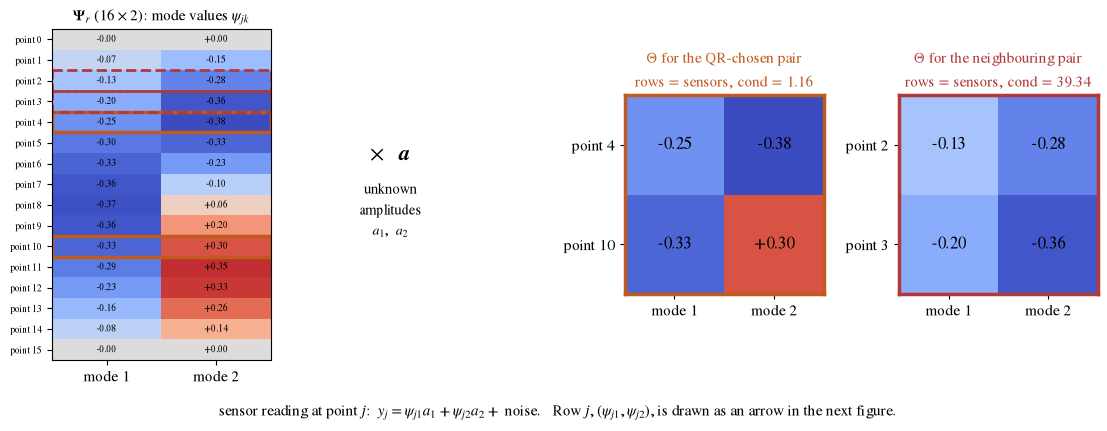

In [9]:
def plot_r2_matrices():
    from matplotlib.patches import Rectangle
    lim = np.abs(PSI_R2).max()
    fig = plt.figure(figsize=(13.5, 4.3))
    gs = fig.add_gridspec(1, 5, width_ratios=[2.2, 0.9, 0.4, 2.0, 2.0], wspace=0.5)
    a = fig.add_subplot(gs[0])
    a.imshow(PSI_R2, cmap='coolwarm', vmin=-lim, vmax=lim, aspect='auto')
    for j in range(N_R2):
        for k in range(2):
            a.text(k, j, f'{PSI_R2[j, k]:+.2f}', ha='center', va='center', fontsize=7, color='black')
    for j in GOOD_R2:
        a.add_patch(Rectangle((-0.5, j - 0.5), 2, 1, fill=False, ec='C1', lw=2.5))
    for j in BAD_R2:
        a.add_patch(Rectangle((-0.5, j - 0.5), 2, 1, fill=False, ec='C3', lw=2, ls='--'))
    a.set_xticks([0, 1]); a.set_xticklabels(['mode 1', 'mode 2'])
    a.set_yticks(range(N_R2)); a.set_yticklabels([f'point {j}' for j in range(N_R2)], fontsize=7)
    a.set_title(r'$\boldsymbol{\Psi}_r$ ($16\times2$): mode values $\psi_{jk}$', fontsize=11)
    a.grid(False)
    b = fig.add_subplot(gs[1])
    b.axis('off')
    b.text(0.5, 0.62, r'$\times\ \ \boldsymbol{a}$', ha='center', va='center', fontsize=16)
    b.text(0.5, 0.45, 'unknown\namplitudes\n$a_1,\\ a_2$', ha='center', va='center', fontsize=10)
    for pos, idx, T, col, name, c in [(3, GOOD_R2, T_good, 'C1', 'QR-chosen pair', cond_good),
                                      (4, BAD_R2, T_bad, 'C3', 'neighbouring pair', cond_bad)]:
        a2 = fig.add_subplot(gs[pos])
        a2.imshow(T, cmap='coolwarm', vmin=-lim, vmax=lim, aspect='equal')
        for r_ in range(2):
            for k in range(2):
                a2.text(k, r_, f'{T[r_, k]:+.2f}', ha='center', va='center', fontsize=12, color='black')
        a2.set_xticks([0, 1]); a2.set_xticklabels(['mode 1', 'mode 2'])
        a2.set_yticks([0, 1]); a2.set_yticklabels([f'point {j}' for j in idx])
        for sp in a2.spines.values():
            sp.set_color(col); sp.set_linewidth(2.5)
        a2.set_title(f'$\\Theta$ for the {name}\n'
                     f'rows = sensors, cond = {c:.2f}', fontsize=11, color=col)
        a2.grid(False)
    fig.text(0.5, -0.02, r'sensor reading at point $j$:  $y_j=\psi_{j1}a_1+\psi_{j2}a_2+$ noise.   '
             r'Row $j$, $(\psi_{j1},\psi_{j2})$, is drawn as an arrow in the next figure.',
             ha='center', fontsize=11)


save_dual(plot_r2_matrices, 'osp_r2_matrices', FIG)
plt.show()

**How to read this figure.** Left: the POD basis $\boldsymbol{\Psi}_r$,
one row per grid point and one column per mode, with each mode value
printed in its cell. Multiplying by the unknown amplitudes
$\boldsymbol{a}=(a_1,a_2)$ gives the field at every point. The orange boxes
are the rows of the QR-chosen sensors (points 4 and 10), the dashed red boxes
the neighbouring pair (points 2 and 3). Right: the two $2\times2$ matrices
$\boldsymbol{\Theta}$ those choices produce.

**What it shows.** At points 4 and 10 the two mode values have the same
sign in one row and opposite signs in the other, so the two rows of
$\boldsymbol{\Theta}$ are very different and the condition number is 1.16.
At points 2 and 3 the two rows are almost proportional (both modes have the
same sign and similar ratio), so the two sensors give nearly the same
equation twice and the condition number is 39.34.

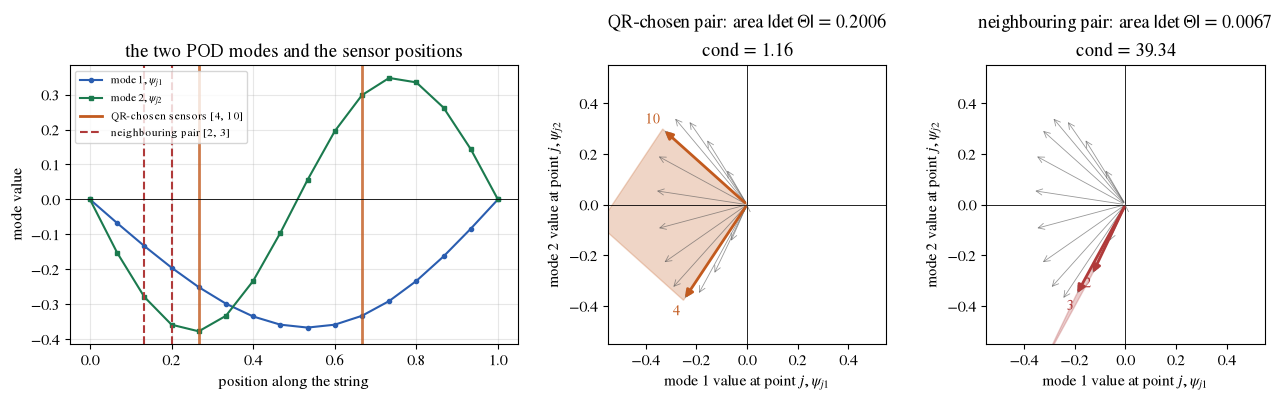

In [10]:
def plot_r2_setup():
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.9),
                           gridspec_kw=dict(width_ratios=[1.5, 1, 1]))
    a0 = ax[0]
    a0.plot(xi_r2, PSI_R2[:, 0], 'o-', color='C0', ms=3, label=r'mode 1, $\psi_{j1}$')
    a0.plot(xi_r2, PSI_R2[:, 1], 's-', color='C2', ms=3, label=r'mode 2, $\psi_{j2}$')
    for j in GOOD_R2:
        a0.axvline(xi_r2[j], color='C1', lw=2, alpha=0.8)
    for j in BAD_R2:
        a0.axvline(xi_r2[j], color='C3', lw=1.5, ls='--')
    a0.axhline(0, color=fg(), lw=0.6)
    a0.set(xlabel='position along the string', ylabel='mode value',
           title='the two POD modes and the sensor positions')
    a0.plot([], [], color='C1', lw=2, label=f'QR-chosen sensors {GOOD_R2.tolist()}')
    a0.plot([], [], color='C3', ls='--', label=f'neighbouring pair {BAD_R2.tolist()}')
    a0.legend(fontsize=8, loc='upper left')
    lim = 0.55
    for a, idx, T, col, name, c, d in [(ax[1], GOOD_R2, T_good, 'C1', 'QR-chosen pair', cond_good, det_good),
                                       (ax[2], BAD_R2, T_bad, 'C3', 'neighbouring pair', cond_bad, det_bad)]:
        for j in range(N_R2):                        # every grid point as a faint arrow
            a.annotate('', PSI_R2[j], (0, 0), arrowprops=dict(arrowstyle='->', color=muted(), lw=0.6, alpha=0.6))
        u, v = T[0], T[1]
        a.fill([0, u[0], u[0] + v[0], v[0]], [0, u[1], u[1] + v[1], v[1]], color=col, alpha=0.25)
        for k, j in enumerate(idx):
            a.annotate('', T[k], (0, 0), arrowprops=dict(arrowstyle='-|>', color=col, lw=2))
            a.text(*(T[k] * 1.12), f'{j}', color=col, ha='center', va='center', fontsize=10)
        a.axhline(0, color=fg(), lw=0.6); a.axvline(0, color=fg(), lw=0.6)
        a.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal',
              xlabel=r'mode 1 value at point $j$, $\psi_{j1}$', ylabel=r'mode 2 value at point $j$, $\psi_{j2}$',
              title=f'{name}: area $|\\det\\Theta|$ = {d:.4f}\ncond = {c:.2f}')
        a.grid(False)
    plt.tight_layout()


save_dual(plot_r2_setup, 'osp_r2_setup', FIG)
plt.show()

**How to read this figure.** Left: the two POD modes along the string
(mode 1 is one arch, mode 2 is one full wave). Solid orange lines mark the
QR-chosen sensors, dashed red lines the neighbouring pair. Middle and right: every grid
point drawn as a faint arrow $\boldsymbol{c}_j=(\psi_{j1},\psi_{j2})$, the
chosen pair as thick arrows (numbers are grid indices), and the shaded
parallelogram they span.

**What it shows.** The QR-chosen sensors sit where the two modes look most
*different*: at point 4 the two modes have the same sign, at point 10
opposite signs. Their arrows point in clearly different directions and
span a large, almost square parallelogram (area 0.2006). The neighbouring
points 2 and 3 see the two modes in nearly the same proportion: their
arrows almost overlap and the parallelogram collapses to a thin sliver
(area 0.0067). Two sensors that say almost the same thing are worth little
more than one.

### Noise in, error out

Now add sensor noise: $\boldsymbol{y}=\boldsymbol{\Theta}\boldsymbol{a}+\boldsymbol{n}$
with independent noise of standard deviation $\eta$ on each reading. The
estimate is $\hat{\boldsymbol{a}}=\boldsymbol{\Theta}^{-1}\boldsymbol{y}$
(with more sensors than modes, the pseudo-inverse
$\boldsymbol{\Theta}^{+}=(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})^{-1}\boldsymbol{\Theta}^\top$).
Substituting $\boldsymbol{y}$:

$$\hat{\boldsymbol{a}}=\boldsymbol{\Theta}^{+}(\boldsymbol{\Theta}\boldsymbol{a}+\boldsymbol{n})
  =\boldsymbol{a}+\underbrace{\boldsymbol{\Theta}^{+}\boldsymbol{n}}_{\text{error }\boldsymbol{e}} .$$

The error is a fixed matrix times the noise. A matrix $\mathbf{M}$ applied
to noise with covariance $\eta^2\mathbf{I}$ gives covariance
$\eta^2\mathbf{M}\mathbf{M}^\top$, so

$$\operatorname{Cov}(\hat{\boldsymbol{a}})=\eta^2\boldsymbol{\Theta}^{+}\boldsymbol{\Theta}^{+\top}
  =\eta^2(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})^{-1}.$$

Repeat the measurement many times and the estimates $\hat{\boldsymbol{a}}$
form a cloud around the truth. Its shape is an ellipse (an ellipsoid when
$r>2$) whose semi-axes point along the right singular vectors of
$\boldsymbol{\Theta}$ and have lengths $\eta/\sigma_1,\dots,\eta/\sigma_r$.
A tiny singular value means a very long axis. The ellipse's area (volume)
is proportional to $\prod_i\eta/\sigma_i=\eta^r/\sqrt{\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})}$.

We test this by simulation: 400 noisy readings for each pair.

In [11]:
noise_r2 = np.random.default_rng(SEED + 7).standard_normal((N_DRAW_R2, 2))
clouds = {}
for name, T in [('good', T_good), ('bad', T_bad)]:
    Y = (T @ A_TRUE_R2)[None, :] + ETA_R2 * noise_r2          # 400 noisy readings
    A_hat = np.linalg.solve(T, Y.T).T                          # 400 estimates of a
    cov_emp = np.cov(A_hat.T)
    cov_th = ETA_R2 ** 2 * np.linalg.inv(T.T @ T)
    clouds[name] = (A_hat, cov_th)
    rms = np.sqrt(np.mean(np.sum((A_hat - A_TRUE_R2) ** 2, axis=1)))
    print(f"{name:4s}: rms error of a_hat {rms:.4f}; predicted axes eta/sigma = "
          f"{np.round(ETA_R2 / np.linalg.svd(T, compute_uv=False), 4)}")
    rel = np.linalg.norm(cov_emp - cov_th) / np.linalg.norm(cov_th)
    assert rel < 0.2, "the simulated cloud must match eta^2 (Theta^T Theta)^{-1}"
area_ratio = np.sqrt(np.linalg.det(clouds['bad'][1]) / np.linalg.det(clouds['good'][1]))
print(f"ellipse area ratio bad/good = {area_ratio:.1f} = |det good| / |det bad| = {det_good / det_bad:.1f}")
assert np.isclose(area_ratio, det_good / det_bad)

good: rms error of a_hat 0.0317; predicted axes eta/sigma = [0.0208 0.024 ]
bad : rms error of a_hat 0.7563; predicted axes eta/sigma = [0.0195 0.7684]
ellipse area ratio bad/good = 30.1 = |det good| / |det bad| = 30.1


**Reading the numbers.** The simulated covariance agrees with
$\eta^2(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})^{-1}$ (checked by the
assert). With noise $\eta=0.01$ on every reading, the QR-chosen pair's ellipse has
two semi-axes of similar length (0.0208 and 0.024), while the neighbouring pair's
ellipse has one semi-axis of 0.7684, about 40 times longer than the other.
Its area is 30.1 times larger, exactly the ratio of the two determinants,
and the typical (rms) error of $\hat{\boldsymbol{a}}$ grows from 0.0317 to
0.7563: the same sensors, the same noise, 24 times the error.

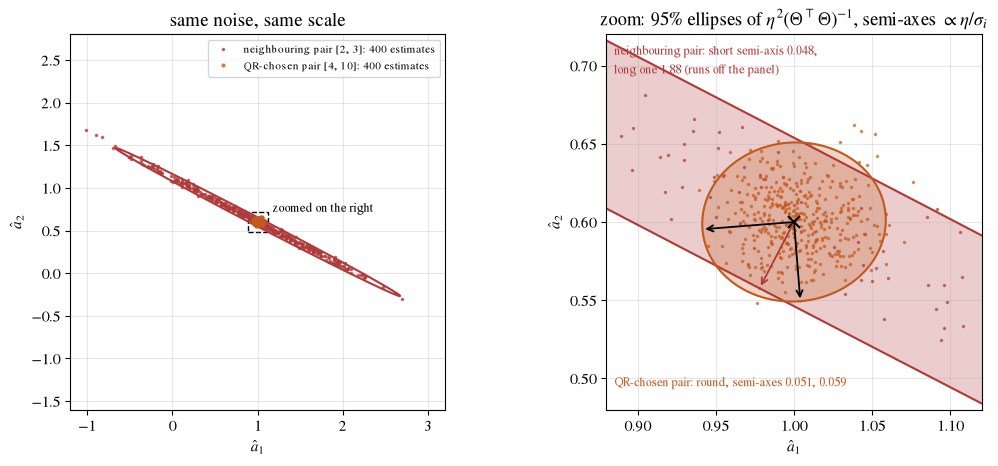

In [12]:
def ellipse_xy(cov, centre, k=np.sqrt(5.991), npts=200):
    w, V = np.linalg.eigh(cov)
    t = np.linspace(0, 2 * np.pi, npts)
    return centre[:, None] + V @ (k * np.sqrt(w)[:, None] * np.vstack([np.cos(t), np.sin(t)]))


def plot_r2_noise():
    from matplotlib.patches import Rectangle
    Z = 0.12                                                   # half-width of the zoom window
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
    # left: both clouds on the same scale
    a = ax[0]
    for key, col, name, ms in [('bad', 'C3', f'neighbouring pair {BAD_R2.tolist()}', 3),
                               ('good', 'C1', f'QR-chosen pair {GOOD_R2.tolist()}', 4)]:
        A_hat, cov_th = clouds[key]
        a.plot(A_hat[:, 0], A_hat[:, 1], '.', color=col, ms=ms, alpha=0.7, label=f'{name}: 400 estimates')
        ex, ey = ellipse_xy(cov_th, A_TRUE_R2)
        a.plot(ex, ey, color=col, lw=1.5)
    a.add_patch(Rectangle(A_TRUE_R2 - Z, 2 * Z, 2 * Z, fill=False, ec=fg(), lw=1, ls='--'))
    a.text(A_TRUE_R2[0] + Z + 0.05, A_TRUE_R2[1] + Z, 'zoomed on the right', fontsize=9)
    a.set(xlim=(A_TRUE_R2[0] - 2.2, A_TRUE_R2[0] + 2.2), ylim=(A_TRUE_R2[1] - 2.2, A_TRUE_R2[1] + 2.2),
          aspect='equal', xlabel=r'$\hat a_1$', ylabel=r'$\hat a_2$',
          title='same noise, same scale')
    a.legend(fontsize=8, loc='upper right')
    # right: zoom on the true a
    a = ax[1]
    for key, col in [('bad', 'C3'), ('good', 'C1')]:
        A_hat, cov_th = clouds[key]
        ex, ey = ellipse_xy(cov_th, A_TRUE_R2, npts=600)
        a.fill(ex, ey, color=col, alpha=0.25); a.plot(ex, ey, color=col, lw=1.5)
        a.plot(A_hat[:, 0], A_hat[:, 1], '.', color=col, ms=3, alpha=0.6)
    wg, Vg = np.linalg.eigh(clouds['good'][1])
    for ev, vec in zip(wg, Vg.T):                               # QR semi-axes
        a.annotate('', A_TRUE_R2 + np.sqrt(5.991 * ev) * vec, A_TRUE_R2,
                   arrowprops=dict(arrowstyle='->', color=fg(), lw=1.3))
    wb, Vb = np.linalg.eigh(clouds['bad'][1])
    a.annotate('', A_TRUE_R2 + np.sqrt(5.991 * wb[0]) * Vb[:, 0], A_TRUE_R2,
               arrowprops=dict(arrowstyle='->', color='C3', lw=1.3))
    a.plot(*A_TRUE_R2, 'x', color=fg(), ms=8, mew=1.5)
    a.text(A_TRUE_R2[0] - 0.115, A_TRUE_R2[1] - 0.105,
           f'QR-chosen pair: round, semi-axes {np.sqrt(5.991*wg[0]):.3f}, {np.sqrt(5.991*wg[1]):.3f}',
           color='C1', fontsize=9)
    a.text(A_TRUE_R2[0] - 0.115, A_TRUE_R2[1] + 0.095,
           f'neighbouring pair: short semi-axis {np.sqrt(5.991*wb[0]):.3f},\nlong one {np.sqrt(5.991*wb[1]):.2f} (runs off the panel)',
           color='C3', fontsize=9)
    a.set(xlim=(A_TRUE_R2[0] - Z, A_TRUE_R2[0] + Z), ylim=(A_TRUE_R2[1] - Z, A_TRUE_R2[1] + Z),
          aspect='equal', xlabel=r'$\hat a_1$', ylabel=r'$\hat a_2$',
          title='zoom: 95% ellipses of $\\eta^2(\\Theta^\\top\\Theta)^{-1}$, semi-axes $\\propto\\eta/\\sigma_i$')
    plt.tight_layout()


save_dual(plot_r2_noise, 'osp_r2_noise', FIG)
plt.show()

**How to read this figure.** Left: each dot is one estimate
$\hat{\boldsymbol{a}}$ from one set of noisy readings (red: neighbouring pair,
orange: QR-chosen pair), the cross is the true $\boldsymbol{a}$, and the curves
are the ellipses predicted by
$\eta^2(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})^{-1}$, which should
contain 95% of the dots. The dashed square is the region shown on the right.
Right: a zoom on the true $\boldsymbol{a}$. The QR-chosen pair's ellipse is small
and round (black arrows: its two semi-axes); the neighbouring pair's ellipse is a
narrow band whose short semi-axis (red arrow) is similar in size, but whose
long semi-axis runs far off the panel. A semi-axis has length proportional
to $\eta/\sigma_i$, so the long axis belongs to the smallest singular value.

**What it shows.** The same sensor noise produces a small round cloud for
the QR-chosen pair and a long thin cloud for the neighbouring pair. Along the thin
direction the neighbouring pair still measures well; along the long direction (the
combination of modes that both neighbouring sensors are blind to) the
error is about 40 times larger. That is what the two quality measures
describe:

* the **condition number** $\sigma_{\max}/\sigma_{\min}$ is how *elongated*
  the ellipse is: the worst-case amplification of relative noise;
* the **determinant** $\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})$
  sets the ellipse's *area* (volume for $r>2$): small determinant, large
  uncertainty region.

Choosing sensors to *maximise the determinant* (D-optimal design) is
choosing them to make this uncertainty region as small as possible.

### QR pivoting, one step at a time

Maximising the determinant over all pairs is a search. QR with column
pivoting does it greedily, and in two dimensions every step can be drawn.
The columns of $\boldsymbol{\Psi}_r^\top$ are the arrows
$\boldsymbol{c}_j$ of the figure above.

1. **Pick the longest arrow.** That grid point is the first sensor; its
   length is $|R_{11}|$.
2. **Remove that direction from every other arrow** (subtract its
   projection onto the chosen arrow). What is left of each arrow is the
   part the first sensor cannot explain.
3. **Pick the longest leftover.** That is the second sensor; the leftover
   length is $|R_{22}|$.

The parallelogram area is base times height, $|R_{11}|\,|R_{22}|$, which is
$|\det\boldsymbol{\Theta}|$. Each step makes the area as large as it can,
given the earlier choices. With $r$ modes the same steps repeat $r$ times.

In [13]:
lengths = np.linalg.norm(PSI_R2, axis=1)
p1 = int(np.argmax(lengths))                       # step 1
q1 = PSI_R2[p1] / lengths[p1]
resid = PSI_R2 - np.outer(PSI_R2 @ q1, q1)          # step 2: remove the q1 direction
p2 = int(np.argmax(np.linalg.norm(resid, axis=1)))  # step 3
R11, R22 = lengths[p1], np.linalg.norm(resid[p2])
print(f"step 1: longest arrow at grid point {p1}, |R11| = {R11:.4f}")
print(f"step 3: largest leftover at grid point {p2}, |R22| = {R22:.4f}")
print(f"area |R11| |R22| = {R11 * R22:.4f};  |det Theta| = {det_good:.4f}")
assert sorted([p1, p2]) == sorted(GOOD_R2.tolist()), "hand-made greedy steps must match scipy's pivoted QR"
assert np.isclose(R11 * R22, det_good)

step 1: longest arrow at grid point 4, |R11| = 0.4533
step 3: largest leftover at grid point 10, |R22| = 0.4426
area |R11| |R22| = 0.2006;  |det Theta| = 0.2006


**Reading the numbers.** The greedy steps by hand pick grid points 4 and
10, the same pair as `scipy.linalg.qr(..., pivoting=True)`, and the product
of the two lengths equals $|\det\boldsymbol{\Theta}|=0.2006$.

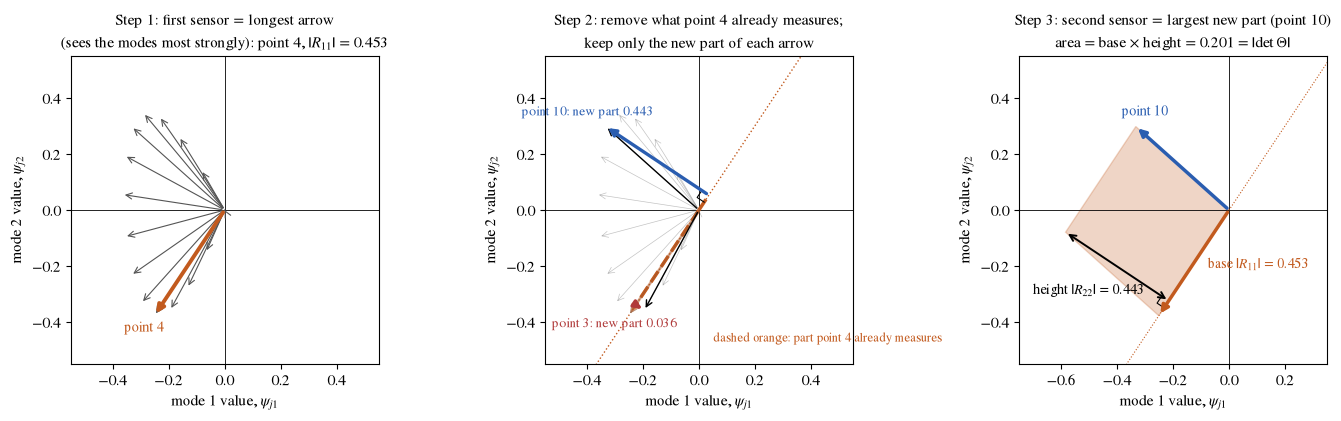

In [14]:
def plot_qr_steps():
    fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.8))
    lim = 0.55
    for a in ax:
        a.axhline(0, color=fg(), lw=0.6); a.axvline(0, color=fg(), lw=0.6)
        a.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect='equal',
              xlabel=r'mode 1 value, $\psi_{j1}$', ylabel=r'mode 2 value, $\psi_{j2}$'); a.grid(False)
    # ---- step 1: all arrows, the longest one highlighted
    for j in range(N_R2):
        ax[0].annotate('', PSI_R2[j], (0, 0), arrowprops=dict(arrowstyle='->', color=muted(), lw=0.8))
    ax[0].annotate('', PSI_R2[p1], (0, 0), arrowprops=dict(arrowstyle='-|>', color='C1', lw=2.8))
    ax[0].text(*(PSI_R2[p1] * 1.15), f'point {p1}', color='C1', ha='center', fontsize=10)
    ax[0].set_title(f'Step 1: first sensor = longest arrow\n(sees the modes most strongly): point {p1}, $|R_{{11}}|$ = {R11:.3f}', fontsize=11)
    # ---- step 2: split two example arrows into "already measured" + "new"
    def right_angle(a, foot, back, perp, size=0.03):
        pts = np.array([foot + size * back, foot + size * back + size * perp, foot + size * perp])
        a.plot(pts[:, 0], pts[:, 1], color=fg(), lw=0.8)
    a = ax[1]
    a.plot([-2 * q1[0], 2 * q1[0]], [-2 * q1[1], 2 * q1[1]], color='C1', lw=1, ls=':')
    a.annotate('', PSI_R2[p1], (0, 0), arrowprops=dict(arrowstyle='-|>', color='C1', lw=2.0, alpha=0.5))
    for j in range(N_R2):
        a.annotate('', PSI_R2[j], (0, 0), arrowprops=dict(arrowstyle='->', color=muted(), lw=0.5, alpha=0.35))
    for j, col, off in [(p2, 'C0', np.array([-0.30, 0.04])), (int(BAD_R2[1]), 'C3', np.array([-0.33, -0.06]))]:
        c = PSI_R2[j]; along = (c @ q1) * q1; left = c - along
        a.annotate('', c, (0, 0), arrowprops=dict(arrowstyle='->', color=fg(), lw=1.0))
        a.plot([0, along[0]], [0, along[1]], color='C1', lw=2.5, ls='--')            # already measured
        a.annotate('', c, along, arrowprops=dict(arrowstyle='-|>', color=col, lw=2.4))  # new part
        if np.linalg.norm(left) > 0.05:
            right_angle(a, along, -q1 * np.sign(c @ q1), left / np.linalg.norm(left))
        a.text(*(c + off), f'point {j}: new part {np.linalg.norm(left):.3f}', color=col, fontsize=9.5)
    a.text(0.05, -0.47, 'dashed orange: part point ' + f'{p1}' + ' already measures', color='C1', fontsize=9)
    a.set_title(f'Step 2: remove what point {p1} already measures;\nkeep only the new part of each arrow', fontsize=11)
    # ---- step 3: parallelogram, base x height
    a = ax[2]
    u, v = PSI_R2[p1], PSI_R2[p2]
    a.fill([0, u[0], u[0] + v[0], v[0]], [0, u[1], u[1] + v[1], v[1]], color='C1', alpha=0.25)
    a.annotate('', u, (0, 0), arrowprops=dict(arrowstyle='-|>', color='C1', lw=2.5))
    a.annotate('', v, (0, 0), arrowprops=dict(arrowstyle='-|>', color='C0', lw=2.5))
    foot = u + (v @ q1) * q1                                      # perpendicular from the far corner
    a.plot([-2 * q1[0], 2 * q1[0]], [-2 * q1[1], 2 * q1[1]], color='C1', lw=0.8, ls=':')
    a.annotate('', u + v, foot, arrowprops=dict(arrowstyle='<->', color=fg(), lw=1.4))
    right_angle(a, foot, -q1 * np.sign(v @ q1) if abs(v @ q1) > 1e-9 else -q1, (u + v - foot) / np.linalg.norm(u + v - foot))
    a.text(*(u * 0.5 + np.array([0.05, -0.02])), f'base $|R_{{11}}|$ = {R11:.3f}', color='C1', fontsize=10)
    a.text(*((foot + u + v) / 2 + np.array([-0.30, -0.10])), f'height $|R_{{22}}|$ = {R22:.3f}', fontsize=10)
    a.set(xlim=(-0.75, 0.35), ylim=(-0.55, 0.55))
    a.text(*(v + np.array([-0.05, 0.04])), f'point {p2}', color='C0', fontsize=10)
    a.set_title(f'Step 3: second sensor = largest new part (point {p2})\n'
                f'area = base $\\times$ height = {R11 * R22:.3f} = $|\\det\\Theta|$', fontsize=11)
    plt.tight_layout()


save_dual(plot_qr_steps, 'osp_qr_steps', FIG)
plt.show()

**How to read this figure.** All three panels show the plane of mode
values: an arrow for grid point $j$ ends at $(\psi_{j1},\psi_{j2})$, its row
of $\boldsymbol{\Psi}_r$. Left: all 16 arrows; the longest (orange, point 4)
becomes the first sensor. Middle: two example arrows split into two parts.
The dashed orange part lies along arrow 4: that combination of modes is
already measured by sensor 4. The coloured part, at a right angle to it, is
what a sensor there would add that is new. Right: the two chosen arrows and
their parallelogram, with base $|R_{11}|$ (arrow 4) and height $|R_{22}|$
(the new part of arrow 10, drawn as the perpendicular from the far corner).

**What it shows.** Point 10 points in a very different direction from
point 4, so almost all of it is new (0.443). Point 3 points almost the same
way as point 4, so nearly all of it is already measured and only 0.036 is
new: a sensor there would be close to redundant. The second sensor is the
point with the largest new part, and base times height, $0.453\times0.443=0.201$,
is the parallelogram area $|\det\boldsymbol{\Theta}|$ that the D-optimal
criterion wants large. In the five-mode picture below the same thing
happens in five dimensions: the diagonal of $\mathbf{R}$ lists the new-part
lengths in the order the sensors were picked.

## 4. QR with column pivoting on the five-mode example, $\boldsymbol{\Psi}_r^\top\mathbf{P}=\mathbf{Q}\mathbf{R}$

How the sensors were chosen. Think of $\boldsymbol{\Psi}_r^\top$
($r\times n$) as $n$ column vectors in $\mathbb{R}^r$, one per grid point:
column $j$ says how strongly each mode is present at grid point $j$. Pivoted
QR (Householder QR with column pivoting, `scipy.linalg.qr(..., pivoting=True)`)
then works greedily:

1. Compute the length of every column. Pick the longest one. It is the first
   sensor, and its length is $|R_{11}|$.
2. Remove from all remaining columns their component along the chosen column
   (an orthogonal projection, done with a Householder reflection).
3. Pick the remaining column with the largest leftover length. It is the next
   sensor, and that length is $|R_{22}|$.
4. Repeat until $r$ columns are chosen.

$\mathbf{P}$ is the $n\times n$ permutation matrix that moves the chosen
columns to the front, $\mathbf{Q}$ ($r\times r$) is orthogonal and $\mathbf{R}$
($r\times n$) is upper triangular. Each step adds the column that is "most
new", so it grows the volume spanned by the chosen columns as much as
possible. That volume is $|\det\boldsymbol{\Theta}|=|R_{11}R_{22}\cdots R_{rr}|$,
and for square $\boldsymbol{\Theta}$ we have
$\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})=(\det\boldsymbol{\Theta})^2$:
greedy QR is greedy D-optimal design.

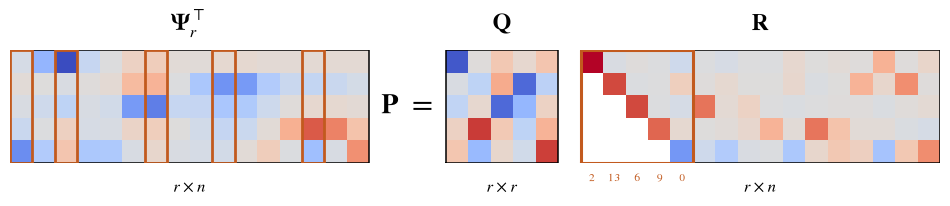

In [15]:
save_dual(plot_osp_qr, 'osp_block_qr', FIG)
plt.show()

**How to read this figure.** Left: $\boldsymbol{\Psi}_r^\top$, $5\times16$, one
column per grid point. The orange boxes mark the five columns chosen as
sensors (grid points 0, 2, 6, 9, 13). The symbol $\mathbf{P}$ stands for the
column permutation. Middle: $\mathbf{Q}$, $5\times5$, orthogonal. Right:
$\mathbf{R}$, $5\times16$, upper triangular; the white cells below the
diagonal are exact zeros. The orange box covers the first $r=5$ columns of
$\mathbf{R}$, i.e. the pivoted columns, and the orange numbers under it are
their grid indices in the order QR picked them: 2, 13, 6, 9, 0.

**What it shows.** The diagonal of $\mathbf{R}$ fades from dark red to lighter
colours (the last entry is negative, hence blue): $|R_{11}|\ge|R_{22}|\ge\dots$, because each new sensor can only add
what the previous ones have not already captured. Grid point 2 is picked
first because its column of $\boldsymbol{\Psi}_r^\top$ is the longest. The
product of the boxed diagonal is the volume $|\det\boldsymbol{\Theta}|$, which
the next cell checks numerically.

In [16]:
assert np.isclose(np.prod(np.abs(np.diag(R_qr))), abs(np.linalg.det(THETA))), \
    "|det Theta| = product of the pivoted R diagonal"

The assert passes: the product of the pivoted diagonal of $\mathbf{R}$ equals
$|\det\boldsymbol{\Theta}|$ for the QR sensor set.

## 5. How close is greedy QR to the true D-optimum?

For $n=32$ grid points and $r=p=4$ there are $\binom{32}{4}=35{,}960$ possible
sensor sets, few enough to evaluate them all. The next cell:

* generates a new field, learns $\boldsymbol{\Psi}_r$ from the **first half** of
  the snapshots only (training), and keeps the second half for testing;
* forms $\boldsymbol{\Theta}$ for every subset at once (an array of shape
  $35{,}960\times4\times4$) and computes
  $\log\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})=2\log|\det\boldsymbol{\Theta}|$
  for each (the $10^{-300}$ avoids $\log 0$);
* finds the QR sensors, the exhaustive best subset, and the fraction of
  subsets with a strictly larger determinant than QR.

In [17]:
xi_b, X_b, _, _ = make_field(N_BF, R_BF, N_SNAP, rng)
X_train, X_test = X_b[:, :N_SNAP // 2], X_b[:, N_SNAP // 2:]
PSI_B = np.linalg.svd(X_train, full_matrices=False)[0][:, :R_BF]   # basis from training half only
subsets = np.array(list(combinations(range(N_BF), R_BF)))
TH = PSI_B[subsets]                                   # (S, r, r)
ld_all = 2 * np.log(np.abs(np.linalg.det(TH)) + 1e-300)
s_qr = qr_sensors(PSI_B, R_BF)
ld_qr = logdet(PSI_B, s_qr)
rank_qr = np.mean(ld_all > ld_qr + 1e-9)               # fraction of subsets strictly better than QR
best = subsets[np.argmax(ld_all)]
print(f"{len(subsets)} subsets. QR sensors {s_qr}: log det = {ld_qr:.2f}; "
      f"best {best}: {ld_all.max():.2f}; random median {np.median(ld_all):.2f}")
print(f"QR beats {100*(1-rank_qr):.2f}% of all subsets; det ratio best/QR = {np.exp(ld_all.max()-ld_qr):.2f}")
assert rank_qr < 0.01, "greedy QR must land in the top 1% of all subsets"
assert ld_all.max() - ld_qr < np.log(5), "QR must be within a factor 5 of the optimal determinant"

35960 subsets. QR sensors [ 4 16 27 31]: log det = -5.21; best [ 4 16 27 31]: -5.21; random median -21.55
QR beats 100.00% of all subsets; det ratio best/QR = 1.00


QR picks grid points $[4, 16, 27, 31]$, which is exactly the exhaustive
optimum: both have $\log\det=-5.21$ and the ratio of determinants is 1.00. No
subset is strictly better (QR "beats 100.00%", ties included). A typical subset
has $\log\det=-21.55$, so its determinant is many orders of magnitude
smaller than the QR one. Finding the optimum exactly is luck of this small
problem: pivoting is greedy and is not guaranteed to find it in general.
Landing in the extreme top tail is the typical behaviour.

### Does a large determinant really mean a small error?

The determinant is only a proxy. What we care about is the reconstruction
error. `recon_err(idx)` measures it on the **held-out** snapshots
$\mathbf{X}_{\text{test}}$: it reads the field at the sensors, adds noise of
standard deviation `NOISE` times the field RMS (2%), solves the least-squares
problem for all test snapshots at once, and returns the relative error

$$e=\frac{\|\boldsymbol{\Psi}_r\hat{\mathbf{A}}-\mathbf{X}_{\text{test}}\|_F}{\|\mathbf{X}_{\text{test}}\|_F},$$

where $\hat{\mathbf{A}}$ holds the estimated coefficients of all test snapshots
as columns and $\|\cdot\|_F$ is the Frobenius norm. One fixed noise record is
used for every subset, so all subsets are compared under identical noise.
Evaluating every subset would be slow, so we use a random sample of 3000
subsets, plus QR and the optimum, and compute the correlation between
$\log\det$ and $\log e$ over the sample.

In [18]:
# error of each subset on held-out snapshots (sample of subsets + QR + best)
rms = np.sqrt(np.mean(X_test ** 2))
NOISE_MAT = np.random.default_rng(1).standard_normal(X_test.shape)   # one noise record per grid point


def recon_err(idx):
    Th = PSI_B[idx]
    Y = X_test[idx] + NOISE * rms * NOISE_MAT[idx]      # noisy readings, (p, n_test)
    A = np.linalg.lstsq(Th, Y, rcond=None)[0]           # gappy POD: least-squares coefficients
    return np.linalg.norm(PSI_B @ A - X_test) / np.linalg.norm(X_test)


sample = rng.choice(len(subsets), 3000, replace=False)
err_s = np.array([recon_err(subsets[i]) for i in sample])
err_qr, err_best = recon_err(s_qr), recon_err(best)
err_med = np.median(err_s)
corr = np.corrcoef(ld_all[sample], np.log(err_s))[0, 1]
print(f"held-out error: QR {err_qr:.4f}, D-optimal {err_best:.4f}, random median {err_med:.4f}; "
      f"corr(log det, log err) = {corr:.2f}")
assert err_med / err_qr > 3, "QR must beat a typical random subset by a wide margin"
assert corr < -0.7, "larger det(Theta^T Theta) must mean smaller error"

held-out error: QR 0.0142, D-optimal 0.0142, random median 2.7150; corr(log det, log err) = -0.93


With 2% sensor noise, QR (and the identical D-optimal set) reconstructs the
unseen snapshots with relative error 0.0142, while the median random subset
gives 2.7150, i.e. an error larger than the field itself. The correlation of
$-0.93$ between $\log\det$ and $\log e$ confirms that the determinant is a good
predictor of the real error. The next cell plots both results.

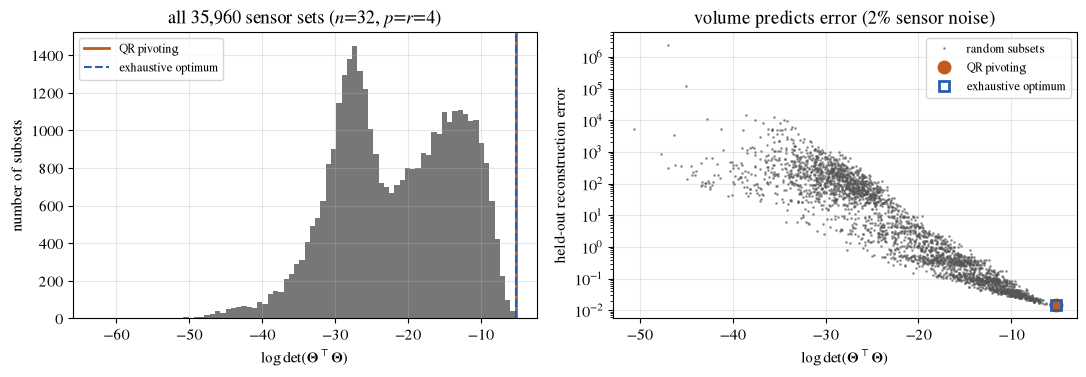

In [19]:
def plot_dopt():
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
    ax[0].hist(ld_all, bins=80, color=muted(), alpha=0.8)
    ax[0].axvline(ld_qr, color='C1', lw=2, label='QR pivoting')
    ax[0].axvline(ld_all.max(), color='C0', lw=1.5, ls='--', label='exhaustive optimum')
    ax[0].set(xlabel=r'$\log\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})$', ylabel='number of subsets',
              title=f'all {len(subsets):,} sensor sets ($n$={N_BF}, $p$=$r$={R_BF})')
    ax[0].legend(fontsize=9)
    ax[1].semilogy(ld_all[sample], err_s, '.', ms=2, color=muted(), alpha=0.5, label='random subsets')
    ax[1].semilogy([ld_qr], [err_qr], 'o', color='C1', ms=9, label='QR pivoting')
    ax[1].semilogy([ld_all.max()], [err_best], 's', color='C0', ms=7, mfc='none', mew=2,
                   label='exhaustive optimum')
    ax[1].set(xlabel=r'$\log\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})$',
              ylabel='held-out reconstruction error', title=f'volume predicts error ({100*NOISE:.0f}% sensor noise)')
    ax[1].legend(fontsize=9); plt.tight_layout()


save_dual(plot_dopt, 'osp_dopt', FIG)
plt.show()

**How to read this figure.** Left panel: a histogram of
$\log\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})$ over all 35,960 sensor
sets (horizontal axis), with the number of sets in each bin on the vertical
axis. The solid orange line is the QR set, the dashed blue line the
exhaustive optimum; here they lie on top of each other at the far right edge.
Right panel: one grey dot per sampled subset, with $\log\det$ on the horizontal
axis and the held-out relative reconstruction error on a logarithmic vertical
axis. The orange dot is QR and the open blue square the exhaustive optimum;
they coincide in the bottom-right corner.

**What it shows.** Almost all subsets sit far to the left of QR: the median
is $-21.55$ against $-5.21$ for QR, and only a thin tail of subsets comes
close to the orange line. On the right, the dots
form a clear band falling from upper left to lower right (correlation
$-0.93$): more volume means less error, over several orders of magnitude. QR
sits at the best end of that band with error 0.0142, versus 2.7150 for the
median subset. One cheap QR factorisation did as well as checking all 35,960
sets.

## 6. Oversampling, $p>r$

With more sensors than modes, $\boldsymbol{\Psi}_r^\top$ is no longer enough:
it has only $r$ rows, so after $r$ pivots every remaining column has zero
leftover length and the greedy ranking stops being meaningful. The standard
fix is to pivot on the $n\times n$ matrix
$\boldsymbol{\Psi}_r\boldsymbol{\Psi}_r^\top$ (rank $r$). Its column $j$ is
$\boldsymbol{\Psi}_r$ times column $j$ of $\boldsymbol{\Psi}_r^\top$, and
multiplying by $\boldsymbol{\Psi}_r$ (orthonormal columns) preserves lengths
and angles. So the first $r$ pivots are the same as before, and the
factorisation continues to produce an ordering of all $n$ points that we use
for $p>r$. This extension is a heuristic; the experiment below checks how well
it works.

For every $p$ in `P_OVER` the cell computes $\log\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})$
for the QR set and for `N_RAND` = 500 random sets, and prints the QR advantage
(QR minus the median random value).

In [20]:
ld_q, ld_r = [], []
for p in P_OVER:
    ld_q.append(logdet(PSI_B, qr_sensors(PSI_B, p)))
    ld_r.append([logdet(PSI_B, np.sort(rng.choice(N_BF, p, replace=False))) for _ in range(N_RAND)])
ld_q, ld_r = np.array(ld_q), np.array(ld_r)            # ld_r has shape (len(P_OVER), N_RAND)
adv = ld_q - np.median(ld_r, axis=1)
print("p        :", list(P_OVER))
print("QR - median random log det:", np.round(adv, 2))
assert np.all(ld_q >= np.percentile(ld_r, 90, axis=1)), "QR must beat 90% of random sets at every p"
assert adv[0] > adv[-1], "the QR advantage must shrink with oversampling"

p        : [4, 5, 6, 7, 8, 9, 10, 11, 12]
QR - median random log det: [15.81  9.89  6.44  5.65  4.35  3.99  3.79  3.18  3.  ]


The QR advantage in $\log\det$ falls steadily from 15.81 at $p=4$ to 3.00 at
$p=12$. QR still beats at least 90% of the random sets at every $p$ (the first
assert), but the gap shrinks as sensors are added.

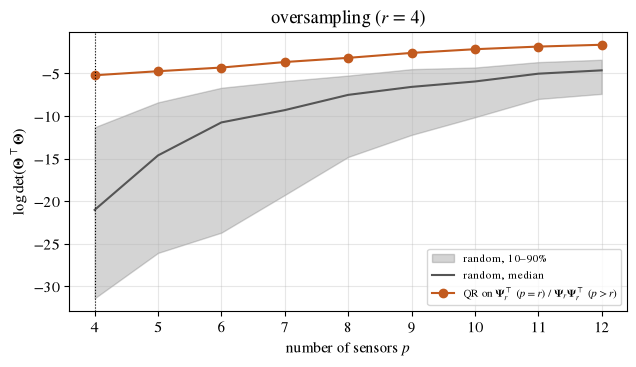

In [21]:
def plot_oversampling():
    P = np.array(list(P_OVER))
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    ax.fill_between(P, np.percentile(ld_r, 10, axis=1), np.percentile(ld_r, 90, axis=1),
                    color=muted(), alpha=0.25, label='random, 10–90%')
    ax.plot(P, np.median(ld_r, axis=1), color=muted(), lw=1.5, label='random, median')
    ax.plot(P, ld_q, 'o-', color='C1', label=r'QR on $\boldsymbol{\Psi}_r^\top$ ($p=r$) / '
                                              r'$\boldsymbol{\Psi}_r\boldsymbol{\Psi}_r^\top$ ($p>r$)')
    ax.axvline(R_BF, color=fg(), lw=0.8, ls=':')
    ax.set(xlabel='number of sensors $p$', ylabel=r'$\log\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})$',
           title=f'oversampling ($r$ = {R_BF})')
    ax.legend(fontsize=8, loc='lower right'); plt.tight_layout()


save_dual(plot_oversampling, 'osp_oversampling', FIG)
plt.show()

**How to read this figure.** Horizontal axis: the number of sensors $p$, from 4
to 12. Vertical axis: $\log\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})$,
higher is better. The grey band covers the 10th to 90th percentile of the 500
random sets at each $p$, and the dark grey line is their median. The orange
line with dots is QR. The dotted vertical line marks $p=r=4$, the smallest
number of sensors that can determine 4 coefficients.

**What it shows.** At $p=r$ the gap between QR and the random median is
largest (15.81 in $\log\det$), and the random band is very wide: random
placement is a gamble. As $p$ grows the band narrows and rises towards the
QR curve, and the advantage falls to 3.00 at $p=12$. With many sensors almost
any set conditions $\boldsymbol{\Theta}$ well, so careful placement matters
most when sensors are few.

## Summary

* Learn $\boldsymbol{\Psi}_r$ from data with the SVD. The unknown shrinks from
  $n$ field values to $r$ modal coefficients, so $p=r$ well-placed point
  sensors suffice.
* The noise in the estimate has covariance
  $\eta^2(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})^{-1}$, so a good sensor set
  maximises $\det(\boldsymbol{\Theta}^\top\boldsymbol{\Theta})$. Here that volume
  predicted the measured reconstruction error (correlation $-0.93$).
* QR with column pivoting finds a near-D-optimal set greedily in one
  factorisation instead of $\binom{n}{p}$ determinant evaluations. On the
  35,960-subset problem it found the exact optimum.
* For $p>r$, pivot on $\boldsymbol{\Psi}_r\boldsymbol{\Psi}_r^\top$. The
  advantage over random placement is largest at $p=r$ and shrinks with
  oversampling.
* The full-scale test on a wind-farm wake is `cs_sensor_placement`.

## Try this

All settings are in the **Parameters (edit these)** cell near the top.

1. Change `SEED` to a few other values and rerun. Does QR still hit the
   exhaustive optimum, or only land in the top tail of the histogram?
2. Raise `NOISE` from 0.02 to 0.1. Which errors in the right panel of the
   D-optimality figure grow, and does the correlation between $\log\det$ and
   error change?
3. Increase `N_BF` to 40 (keep `R_BF = 4`). The number of subsets becomes
   $\binom{40}{4}=91{,}390$. How much longer does the brute force take, and is
   QR still at the top?
4. Replace `qr_sensors(PSI_B, R_BF)` by a uniformly spaced set such as
   `np.linspace(0, N_BF - 1, R_BF).astype(int)` and compare its $\log\det$ and
   held-out error with QR.